Copyright: Vrije Universiteit Amsterdam, Faculty of Humanities, CLTL

# Lab 5.2: Bag-of-words

In this lab, we see how sentences can be interpreted as a bag of words. 

## 1. Average word vectors

A simple way to get a sentence representation is taking the average of its word vectors. This representation ignores word order though. We use the same model and data as in the previous lab. Adjust the data path to point to the correct folder. 

In [1]:
from gensim.models import KeyedVectors
print("loading")
word2vec_model  = KeyedVectors.load_word2vec_format("../data/wiki-news-300d-1M.vec")
print("done loading")

loading
done loading


We can simply concatenate the vectors from all words, but this has the disadvantage that the number of dimensions of the sentence vector depends on the number of words. Alternatively, it is common to take the mean or the sum of the word vectors using the module *numpy*. **Make sure you understand [what it means](https://www.tutorialspoint.com/numpy/numpy_statistical_functions.htm) to calculate the mean of a vector along different axes.**   

In [2]:
import numpy as np

# A function that takes a sentence as a list of tokens and returns the mean vector for a given model
def get_sentence_vector(sentence, model): 
    word_vectors =[]
    for word in sentence: 
        # Ignore words that are not in the vocabulary
        try: 
            index = model.key_to_index[word]
            word_vectors.append(model.get_vector(word))
        except:
            continue
    
    word_matrix = np.asarray(word_vectors)
    mean_vector = np.mean(word_matrix, axis=0)
    sum_vector = np.sum(word_matrix, axis=0)

    return mean_vector, sum_vector

sentence = ["What", "a", "lovely", "day"]

# The mean vector has the same number of dimensions (300) as the individual word vectors
print(get_sentence_vector(sentence, word2vec_model)[0].shape)

(300,)


Similarly as with word vectors, we can calculate the cosine similarity between two sentence vectors. However, conceptually this similarity is hard to interpret. 

**Think about the following questions: When are two sentences similar? How can we interpret the mean of words? Do you think this is a useful representation for sentences?** 

In [3]:
from scipy.spatial import distance
sentence1 = ["Vegans", "just", "live", "longer"]
sentence2 = ["Veganism", "is", "a", "form", "of", "extremism"]
s1_vector = get_sentence_vector(sentence1, word2vec_model)[0]
s2_vector = get_sentence_vector(sentence2, word2vec_model)[0]
similarity = 1- distance.cosine(s1_vector,s2_vector)
print(sentence1)
print(sentence2)
print("Cosine Similarity: " + str(similarity))

['Vegans', 'just', 'live', 'longer']
['Veganism', 'is', 'a', 'form', 'of', 'extremism']
Cosine Similarity: 0.6806071704125757


 **Play around with different sentences. Does it make a difference if we take the mean or the sum?**
 
You can apply pre-processing to the sentences before calculating the sentence vector. **Try out different pre-processing techniques (e.g. lemmatization, stop word removal, only keep most/least frequent words) and compare the effect on the similarity.**

Now it is your turn: get the vectors for all sentences in your dataset. **The code below is incomplete and won't run correctly. Modify it to work with your dataset.** 

In [9]:
import csv
file_path = '../../../Assignments/Assignment 2/Assignment 2/Final_df.csv'

newline_char = '\n'
csv_data = []

with open(file_path, "r", encoding="utf-8", newline=newline_char) as csvfile:
    reader = csv.reader(csvfile, delimiter=",")  # Use '\t' for TSV
    for row in reader:
        csv_data.append(row)

hindi_sents = []
english_sents = []
for i,row in enumerate(csv_data):
    hindi_s = row[2]
    english_s = row[1]
    hindi_sents.append(hindi_s)
    english_sents.append((i,english_s))

sent_id2vector ={}
sent_id2string ={}
# For article in your dataset:
for tupl in english_sents:
    sent_vector = get_sentence_vector(tupl[1],word2vec_model)
    sent_id2string [tupl[0]]= tupl[1]
    sent_id2vector[tupl[0]] = sent_vector
print(sent_id2vector[0])
# print(sent_id2string)

(array([-1.26571432e-01,  5.05000018e-02, -7.77999982e-02,  2.94285640e-03,
        6.40857145e-02,  6.94285566e-03,  2.53142882e-02,  1.70714296e-02,
        1.37185708e-01,  6.52000010e-02, -2.03428566e-02, -3.84142809e-02,
        4.31999974e-02, -5.50999977e-02, -3.45428586e-02,  2.31714305e-02,
        1.46285733e-02,  2.14428566e-02, -2.67142756e-03,  4.73857149e-02,
       -2.22571399e-02, -1.97285697e-01, -8.35285783e-02, -1.44999987e-02,
       -7.28428587e-02, -6.14142828e-02,  6.69285730e-02,  1.36342853e-01,
        4.91571426e-02, -1.05200000e-01,  6.97000027e-02,  3.61428526e-03,
       -7.58571271e-03,  4.08571353e-03,  5.97857162e-02,  2.97999997e-02,
       -3.48142907e-02,  6.67571425e-02,  7.33714253e-02, -2.48571485e-03,
       -1.63999982e-02,  4.09000032e-02, -9.42857191e-02, -2.19999999e-03,
        1.97142866e-02, -3.85714206e-03,  4.08571446e-03,  4.96142842e-02,
        9.39142853e-02,  2.58571282e-03, -1.88000016e-02, -5.64857125e-02,
       -6.56857133e-01, 

Here is a little toy example how to calculate the similarity between all possible pairs. **Make sure you understand how to read the similarity matrix**. 

In [10]:
from sklearn.metrics.pairwise import cosine_similarity

# Toy example: 
sentId2string ={"a1_s1":"Vegans just live longer", "a2_s1":"Veganism is a form of extremism","a3_s3":"Eating vegan is hard", "a4_s1":"How to build a car"  }

ids =[]
vectors =[]
for id, text in sentId2string.items():
    sentence_vector = get_sentence_vector(text.split(" "), word2vec_model)[0]
    ids.append(id)
    vectors.append(sentence_vector)

    
# Calculate the similarity between all possible pairs
similarity_matrix = cosine_similarity(np.asarray(vectors))
print(similarity_matrix)


[[1.0000006  0.68060726 0.71510977 0.6394399 ]
 [0.68060726 1.0000002  0.7497687  0.71026266]
 [0.71510977 0.7497687  1.0000004  0.6026504 ]
 [0.6394399  0.71026266 0.6026504  0.99999964]]


We can use *np.where* to retrieve only the matrix entries with a value above a certain threshold.

In [11]:
threshold = 0.7
# We only want sentence pairs with a similarity above a threshold
result = np.where(similarity_matrix >threshold)
filtered_pairs= list(zip(result[0], result[1]))

for x,y in filtered_pairs:
    # We only look the lower triangle of the similarity matrix because it is symmetric 
    # and the values in the diagonal are always 1.
    if x < y:
        print("Highly similar pair: ")
       
        # x and y refer to the coordinates in the similarity matrix. We need to map them back to sentence ids
        print(ids[x], ids[y])
        print(sentId2string[ids[x]])
        print(sentId2string[ids[y]])
        print()

Highly similar pair: 
a1_s1 a3_s3
Vegans just live longer
Eating vegan is hard

Highly similar pair: 
a2_s1 a3_s3
Veganism is a form of extremism
Eating vegan is hard

Highly similar pair: 
a2_s1 a4_s1
Veganism is a form of extremism
How to build a car



## 3. Plotting heatmaps

Matrices can nicely be visualized using *seaborn*. **Check the [documentation](https://seaborn.pydata.org/generated/seaborn.heatmap.html).** 

If the heatmap is symmetric, it is good practice to only plot half of the matrix. **Change the plot to omit the mask=mask argument and take note of the difference.**

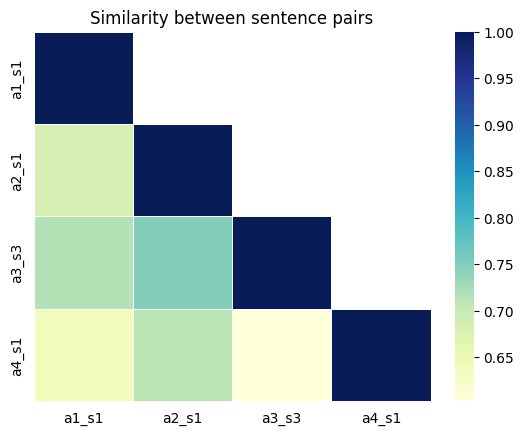

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# create a mask to hide the upper triangle
mask = np.triu(np.ones_like(similarity_matrix, dtype=bool))
np.fill_diagonal(mask, False)

# check the difference between using the mask argument and omitting it
ax = sns.heatmap(similarity_matrix, mask=mask, linewidth=0.5, cmap="YlGnBu")


ax.set_xticklabels(ids)
ax.set_yticklabels(ids)
# Remove the ticks, but keep the labels
ax.tick_params(top=False, bottom=False, left=False, right=False, labelleft=True, labelbottom=True)
ax.set_title("Similarity between sentence pairs")
plt.show()

## 4. Document vectors in spacy

If you are using spacy as an nlp pipeline, you can directly get a vector for a document. Check the [documentation](https://spacy.io/usage/vectors-similarity). The document vector is the average over the vectors of the tokens. You need to double-check which pre-trained model is used to obtain the vectors. 

In [13]:
import spacy

spacy_pipeline = spacy.load("en_core_web_sm")
doc = spacy_pipeline("Vegans just live longer")
print(doc.vector)
print(doc.vector.shape)

[ 0.10844833 -0.12025168 -0.53328884 -0.7676291  -0.01842643 -0.1431283
  0.07504287  0.10533611 -0.7973839   0.5530931  -0.80264413  0.04665703
 -0.25504273 -0.01976682 -0.6323863   0.24392171  0.6678939   0.2509013
 -0.51596415 -0.6130712  -0.05842784  0.70449066 -0.47106653 -0.03931841
 -0.22330868 -0.14665645 -0.5887047  -0.19396524 -0.47479403  0.12948045
  0.03451459  0.32614845 -0.19362924 -0.18801123  0.04581352 -0.7524235
 -0.20163366 -0.21381192  0.4598677  -0.8878604  -0.24677613 -0.52321285
 -0.40369642 -0.49884814  0.39403173  0.67746484  0.35399696  0.24784218
  0.01816311  0.58348227  0.17078403  0.37486345 -0.7173829  -0.47670758
  0.5050274  -0.42322665 -0.02965214 -0.35665935 -0.00317228  0.46615064
  0.1370174   0.23471001  0.09156415 -0.36306524  0.33210734  0.3541292
 -0.07022917 -0.28467882  0.65518975 -0.14431567  0.4621076   1.2129219
  0.01517552 -0.03184581  0.04453836  0.31787744  0.8447929  -0.19522586
 -0.29712     0.5073925  -0.72347033  0.3024063   0.2707

In [14]:
doc = spacy_pipeline("Vegans just live longer and have a better life")
print(doc.vector)
print(doc.vector.shape)

[ 0.06313923 -0.10224101 -0.35580105 -0.1782293   0.04263229 -0.26061693
  0.03909711 -0.2848435  -0.5382465   0.20660093 -0.52932364 -0.05493249
 -0.20308025  0.1341882   0.34088728  0.33336836  0.27976117  0.1931763
 -0.25177324 -0.22548161  0.0455562   0.24074432 -0.00413329 -0.31904295
  0.10462078 -0.3247431  -0.2043758   0.01834374  0.08430869  0.0391622
 -0.18582731  0.40587983  0.04112072 -0.2821275   0.35969454 -0.44254935
 -0.37410182 -0.18698238  0.06936631 -0.5304054  -0.12223384 -0.08143809
 -0.12169696 -0.5819186   0.15698664  0.28583562  0.10787279  0.18242362
  0.34562522  0.44960615  0.28992498 -0.03424133 -0.33128417 -0.43152317
  0.6084831   0.02718253 -0.4312455   0.3025223  -0.13596682  0.36333287
 -0.06745466  0.19306584 -0.01711778 -0.06336685  0.11732771  0.08382094
  0.04379201 -0.21466364  0.6724167   0.03242521  0.15452696  0.34353605
 -0.233858    0.17844242 -0.4980419   0.20547235  0.2554807   0.0085702
  0.10115608  0.17502342 -0.41444856  0.12234766  0.06